<a href="https://colab.research.google.com/github/soorbaev/ai-labs/blob/main/campus_life_gpa_lr_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('campus-life-gpa.csv')

df.head()

,student_id,faculty,student_year,sleep_hours_avg,study_hours_week,library_minutes_week,phone_screen_hours_day,cafe_visits_week,coffee_cups_week,stress_1_10,steps_avg_day,commute_minutes,part_time_hours_week,group_study_sessions,gpa
0,S00001,Arts,2,6.8,14.4,154.0,6.7,2,6,8,7852,64,12.1,2,2.56
1,S00002,CS,1,5.5,13.8,200.0,5.4,4,9,7,3147,44,17.7,1,2.49
2,S00003,Business,3,6.6,14.8,195.0,5.9,5,7,8,7962,30,0.0,3,2.39
3,S00004,Arts,3,5.8,10.7,217.0,4.2,3,7,6,8562,22,0.0,0,3.25
4,S00005,Engineering,2,6.5,24.6,339.0,3.8,4,7,5,6575,30,2.2,3,3.65


In [3]:
df.columns

Index(['student_id', 'faculty', 'student_year', 'sleep_hours_avg',
       'study_hours_week', 'library_minutes_week', 'phone_screen_hours_day',
       'cafe_visits_week', 'coffee_cups_week', 'stress_1_10', 'steps_avg_day',
       'commute_minutes', 'part_time_hours_week', 'group_study_sessions',
       'gpa'],
      dtype='object')

### Что означают столбцы?

| Столбец | Смысл |
|---------|--------|
| `student_id` | идентификатор (не признак для модели) |
| `faculty` | факультет (категория) |
| `student_year` | курс (1–4) |
| `sleep_hours_avg` | средний сон (часы) |
| `study_hours_week` | учёба за неделю (часы) |
| `library_minutes_week` | библиотека за неделю (**минуты**) |
| `phone_screen_hours_day` | экран телефона (часы/день) |
| `cafe_visits_week` | визиты в кафе за неделю |
| `coffee_cups_week` | чашки кофе за неделю |
| `stress_1_10` | стресс 1–10 |
| `steps_avg_day` | шаги в день (**тысячи**) |
| `commute_minutes` | дорога до кампуса (мин) |
| `part_time_hours_week` | подработка (часы/нед) |
| `group_study_sessions` | групповые занятия |
| **`gpa`** | **цель:** средний балл семестра |

**Напишите за мной:** сколько строк и столбцов?

In [4]:
df['faculty'].value_counts()

,count
faculty,
CS,1418
Engineering,1127
Bio,888
Business,795
Arts,772


In [5]:
df.shape

(5000, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              5000 non-null   object 
 1   faculty                 5000 non-null   object 
 2   student_year            5000 non-null   int64  
 3   sleep_hours_avg         5000 non-null   float64
 4   study_hours_week        5000 non-null   float64
 5   library_minutes_week    5000 non-null   float64
 6   phone_screen_hours_day  5000 non-null   float64
 7   cafe_visits_week        5000 non-null   int64  
 8   coffee_cups_week        5000 non-null   int64  
 9   stress_1_10             5000 non-null   int64  
 10  steps_avg_day           5000 non-null   int64  
 11  commute_minutes         5000 non-null   int64  
 12  part_time_hours_week    5000 non-null   float64
 13  group_study_sessions    5000 non-null   int64  
 14  gpa                     5000 non-null   

In [7]:
df.describe()

,student_year,sleep_hours_avg,study_hours_week,library_minutes_week,phone_screen_hours_day,cafe_visits_week,coffee_cups_week,stress_1_10,steps_avg_day,commute_minutes,part_time_hours_week,group_study_sessions,gpa
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2.493400,6.765300,16.435720,239.768000,5.190620,4.218600,7.90520,4.893600,7200.863600,26.983600,7.645360,1.793600,3.128902
std,1.110227,1.097648,6.384319,93.831717,1.810862,1.972103,3.40936,1.575302,2255.049205,12.950972,7.204597,1.315654,0.473956
min,1.000000,3.500000,2.000000,0.000000,0.500000,0.000000,0.00000,1.000000,1500.000000,5.000000,0.000000,0.000000,1.510000
25%,2.000000,6.000000,12.100000,176.000000,4.000000,3.000000,5.00000,4.000000,5677.750000,18.000000,0.600000,1.000000,2.800000
50%,2.000000,6.800000,16.300000,238.500000,5.200000,4.000000,8.00000,5.000000,7177.500000,24.000000,5.900000,2.000000,3.125000
75%,3.000000,7.500000,20.800000,303.000000,6.400000,5.000000,10.00000,6.000000,8689.000000,33.000000,13.700000,3.000000,3.470000
max,4.000000,9.500000,37.900000,571.000000,11.500000,12.000000,24.00000,10.000000,16075.000000,95.000000,24.300000,8.000000,4.000000


# Мини - график: Учеба vs GPA

Так проще увидеть, что «линия» вообще имеет смысл.


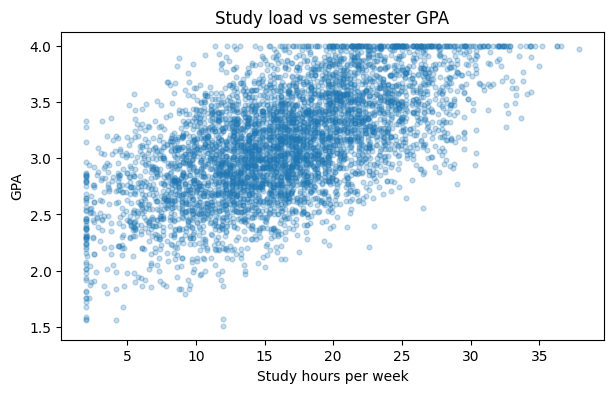

In [8]:
plt.figure(figsize = (7, 4))

plt.scatter(df['study_hours_week'], df['gpa'], alpha = 0.25, s = 12)

plt.xlabel('Study hours per week')
plt.ylabel('GPA')

plt.title('Study load vs semester GPA')

plt.show()

In [9]:
feature_cols = [
       'sleep_hours_avg',
       'study_hours_week',
       'library_minutes_week',
       'phone_screen_hours_day',
       'cafe_visits_week',
       'coffee_cups_week',
       'stress_1_10',
       'steps_avg_day',
       'commute_minutes',
       'part_time_hours_week',
       'group_study_sessions',
       'student_year'
       ]

In [10]:
X = pd.get_dummies(
    df[feature_cols + ['faculty']],
    columns = ['faculty']
)

In [11]:
X.head()

,sleep_hours_avg,study_hours_week,library_minutes_week,phone_screen_hours_day,cafe_visits_week,coffee_cups_week,stress_1_10,steps_avg_day,commute_minutes,part_time_hours_week,group_study_sessions,student_year,faculty_Arts,faculty_Bio,faculty_Business,faculty_CS,faculty_Engineering
0,6.8,14.4,154.0,6.7,2,6,8,7852,64,12.1,2,2,True,False,False,False,False
1,5.5,13.8,200.0,5.4,4,9,7,3147,44,17.7,1,1,False,False,False,True,False
2,6.6,14.8,195.0,5.9,5,7,8,7962,30,0.0,3,3,False,False,True,False,False
3,5.8,10.7,217.0,4.2,3,7,6,8562,22,0.0,0,3,True,False,False,False,False
4,6.5,24.6,339.0,3.8,4,7,5,6575,30,2.2,3,2,False,False,False,False,True


In [12]:
y = df['gpa'].copy()

In [13]:
print("X shape:", X.shape)
print("columns:", list(X.columns))

X shape: (5000, 17)
columns: ['sleep_hours_avg', 'study_hours_week', 'library_minutes_week', 'phone_screen_hours_day', 'cafe_visits_week', 'coffee_cups_week', 'stress_1_10', 'steps_avg_day', 'commute_minutes', 'part_time_hours_week', 'group_study_sessions', 'student_year', 'faculty_Arts', 'faculty_Bio', 'faculty_Business', 'faculty_CS', 'faculty_Engineering']


# Train / test split
Учимся на одной части, проверяем на **новой**

Иначе легко подогнать веса под шум и обмануть себя

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score # коэфициент детерминации

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state = 42
)

print("train:", X_train.shape, "test:", X_test.shape)

train: (3750, 17) test: (1250, 17)


In [16]:
lr = LinearRegression()
lr.fit(X_train, y_train)

pred = lr.predict(X_test)

print("mse:", round(mean_squared_error(y_test, pred), 4))
print("r2_score:", round(r2_score(y_test, pred), 3))

mse: 0.0726
r2_score: 0.683


# Задания на самостоятельную работу

### 1. Добавить Scaling и сравнить r2_score с и без scaling'a

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 1. Обучение БЕЗ масштабирования (у тебя X_train и X_test уже готовы)
lr_no_scale = LinearRegression()
lr_no_scale.fit(X_train, y_train)
r2_no_scale = r2_score(y_test, lr_no_scale.predict(X_test))

# 2. Обучение СО масштабированием (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_scaled = LinearRegression()
lr_scaled.fit(X_train_scaled, y_train)
r2_scaled = r2_score(y_test, lr_scaled.predict(X_test_scaled))

print(f"R2 без scaling: {r2_no_scale:.4f}")
print(f"R2 со scaling:  {r2_scaled:.4f}")

R2 без scaling: 0.6830
R2 со scaling:  0.6830


### 2. Сравнить Ridge vs LinearRegression
Попробуйте взять несколько параметров `alpha` и найдите лучший,
например `alphas = [0.1, 1, 10, 50, 100, 500]`


### Когда Ridge помогает? (интуиция, не формулы)

1. **Мультиколлинеарность** — признаки похожи / сильно связаны (`study_hours` и `library_minutes`, `cafe_visits` и `coffee_cups`). OLS может «раздуть» веса; Ridge делит ответственность аккуратнее.  
2. **Очень большие коэффициенты** — модель слишком чувствительна к шуму; Ridge их ужимает (смотрите столбец `max_|coef|`).  
3. **Мало данных / много признаков** — регуляризация часто стабилизирует тест.  

На большом чистом датасете Ridge и OLS по R² могут быть близки — это нормально. Важно увидеть **идею**: контроль размера весов.


In [18]:
from sklearn.linear_model import Ridge
import numpy as np

alphas = [0.1, 1, 10, 50, 100, 500]

print("LinearRegression R2:", r2_score(y_test, lr_scaled.predict(X_test_scaled)))
print("-" * 40)

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scaled, y_train)

    r2_ridge = r2_score(y_test, ridge.predict(X_test_scaled))
    max_coef = np.max(np.abs(ridge.coef_))

    print(f"Ridge (alpha={a:3}): R2 = {r2_ridge:.4f} | max_|coef| = {max_coef:.4f}")

LinearRegression R2: 0.6829831400300812
----------------------------------------
Ridge (alpha=0.1): R2 = 0.6830 | max_|coef| = 0.2758
Ridge (alpha=  1): R2 = 0.6830 | max_|coef| = 0.2756
Ridge (alpha= 10): R2 = 0.6830 | max_|coef| = 0.2736
Ridge (alpha= 50): R2 = 0.6831 | max_|coef| = 0.2652
Ridge (alpha=100): R2 = 0.6829 | max_|coef| = 0.2559
Ridge (alpha=500): R2 = 0.6751 | max_|coef| = 0.2072


### 3.Обучите `LinearRegression` **только** на двух признаках:
`study_hours_week` и `sleep_hours_avg` (со `StandardScaler` через Pipeline).  
Какой test R²? Насколько хуже полной модели?

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

# 1. Выбираем только два признака из исходного датафрейма (df)
# Замени названия колонок на те, которые требуются по твоему заданию:
features_two = ['study_hours_week', 'sleep_hours_avg']
X_two = df[features_two]
y_target = df['gpa'] # или твоя целевая переменная

# 2. Делаем сплит
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_two, y_target, test_size=0.25, random_state=42
)

# 3. Создаем Pipeline (StandardScaler + LinearRegression)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())
])

# 4. Обучаем и оцениваем
pipeline.fit(X_train_2, y_train_2)
pred_2 = pipeline.predict(X_test_2)
r2_two = r2_score(y_test_2, pred_2)

print(f"Test R2 по двум признакам: {r2_two:.4f}")

Test R2 по двум признакам: 0.4715
